# Structural Timeseries Case Studies: Atmospheric CO2 and Electricity Demand

This notebook ports the TensorFlow Probability case study
[Structural Time Series Modeling Case Studies: Atmospheric CO2 and Electricity Demand](https://www.tensorflow.org/probability/examples/Structural_Time_Series_Modeling_Case_Studies_Atmospheric_CO2_and_Electricity_Demand)
to `pymc_extras.statespace`. The data, models and train/test splits follow the original. The main
difference is the fitting method: the TFP notebook fits a mean-field variational approximation with
200 Adam steps, while here we sample the posterior with NUTS.

Each `tfp.sts` component has a direct counterpart in `pymc_extras.statespace.structural`:

| `tfp.sts` | `pymc_extras.statespace.structural` |
|---|---|
| `LocalLinearTrend` | `LevelTrend(order=2, innovations_order=2)` |
| `Seasonal(num_seasons=s, num_steps_per_season=d)` | `TimeSeasonality(season_length=s, duration=d, innovations=True)` |
| `LinearRegression` | `Regression` |
| `Autoregressive(order=p)` | `Autoregressive(order=p)` |
| observation noise added by `Sum` | `MeasurementError` |

In [1]:
import logging

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import xarray as xr

from pymc_extras.statespace import structural as st

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.constrained_layout.use": True,
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
    }
)

# The rewrite database logs a full traceback every time a rewrite fails to apply. These are
# harmless, but they bury the sampler output.
logging.getLogger("pytensor.graph.rewriting.basic").setLevel(logging.CRITICAL)

In [2]:
seed = sum(map(ord, "Structural Timeseries Case Studies"))
rng = np.random.default_rng(seed)

In [3]:
def add_figure_legend(fig, ax):
    """
    Move the legend entries of ``ax`` into a single centered row beneath ``fig``.

    Parameters
    ----------
    fig : Figure
        Figure that will own the legend.
    ax : Axes
        Axes carrying the labeled artists.
    """
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles=handles,
        labels=labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.05),
        ncol=len(labels),
        frameon=False,
    )


def plot_forecast(data, forecast, n_forecast, ylabel, figsize=(14, 4)):
    """
    Plot an observed series against the posterior forecast mean and 89% HDI.

    Parameters
    ----------
    data : Series
        The full observed series, training and held-out periods together.
    forecast : DataArray
        Forecast draws of the observed series, with ``chain``, ``draw`` and ``time`` dimensions.
    n_forecast : int
        Number of held-out steps at the end of ``data``.
    ylabel : str
        Label for the y-axis.
    figsize : tuple of float, optional
        Figure size in inches. Default (14, 4).

    Returns
    -------
    fig : Figure
        The assembled figure.
    """
    hdi = az.hdi(forecast)
    forecast_time = forecast.coords["time"]

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(data.index, data.values, color="tab:blue", label="Data")
    ax.plot(
        forecast_time,
        forecast.mean(dim=["chain", "draw"]),
        color="tab:orange",
        ls="--",
        label="Mean forecast",
    )
    ax.fill_between(forecast_time, *hdi.values.T, color="tab:orange", alpha=0.25, label="89% HDI")
    ax.axvline(data.index[-n_forecast], color="k", ls=":")
    ax.set(xlabel="Time", ylabel=ylabel)
    add_figure_legend(fig, ax)

    return fig


def forecast_scores(truth, forecast):
    """
    Mean absolute error of the forecast mean, and the share of held-out points inside the 89% HDI.

    Parameters
    ----------
    truth : ndarray
        Held-out observations, one per forecast step.
    forecast : DataArray
        Forecast draws, with ``chain``, ``draw`` and ``time`` dimensions.

    Returns
    -------
    mae : float
    coverage : float
    """
    lower, upper = az.hdi(forecast).values.T
    mae = np.abs(forecast.mean(dim=["chain", "draw"]).values - truth).mean()
    coverage = ((truth >= lower) & (truth <= upper)).mean()
    return mae, coverage


def plot_component_decomposition(components, split_time, figsize=(14, 9)):
    """
    Plot the posterior mean and 89% HDI of each structural component on its own panel.

    Parameters
    ----------
    components : dict mapping str to DataArray
        Panel title to the posterior draws for that component, over the training and forecast
        periods. Each value must carry ``chain``, ``draw`` and ``time`` dimensions.
    split_time : Timestamp
        First forecast step, marked with a vertical line.
    figsize : tuple of float, optional
        Figure size in inches. Default (14, 9).

    Returns
    -------
    fig : Figure
        The assembled figure.
    """
    fig, ax = plt.subplots(len(components), 1, figsize=figsize, sharex=True)

    for axis, (title, data) in zip(fig.axes, components.items()):
        hdi = az.hdi(data)
        time = data.coords["time"]
        axis.plot(time, data.mean(dim=["chain", "draw"]), color="tab:blue", label="Posterior mean")
        axis.fill_between(time, *hdi.values.T, color="tab:blue", alpha=0.15, label="89% HDI")
        axis.axvline(split_time, color="tab:red", ls="--")
        axis.set_title(title)

    fig.axes[-1].set_xlabel("Time")
    add_figure_legend(fig, fig.axes[0])

    return fig

## Atmospheric CO2

### Data

Monthly mean CO2 concentration measured at the Mauna Loa observatory, January 1966 to January 2019
([NOAA GML](https://gml.noaa.gov/ccgg/trends/)). As in the original, we hold out the last ten years
to evaluate the forecast.

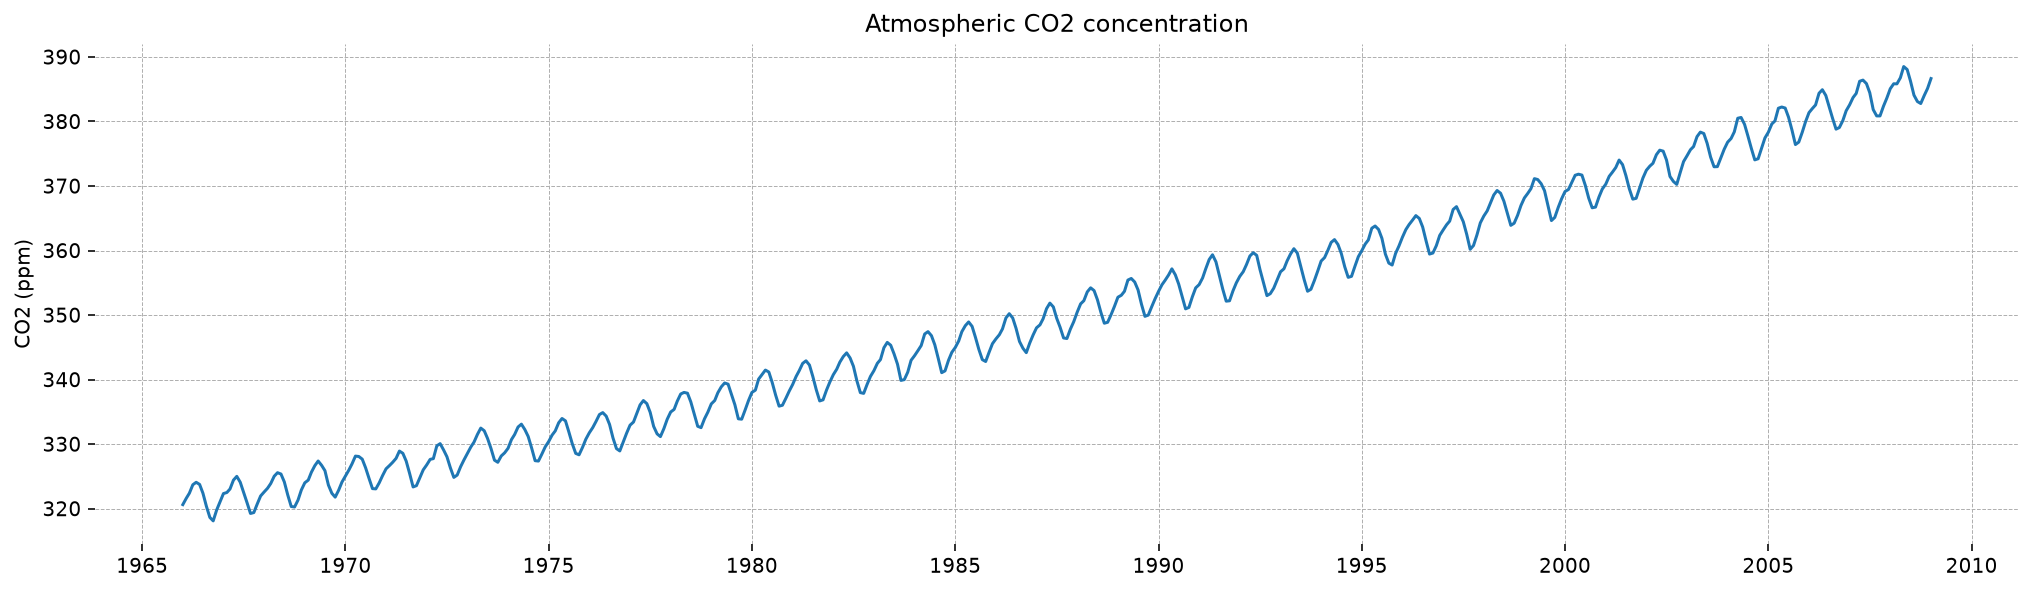

In [4]:
co2 = pd.read_csv("../tests/statespace/_data/mauna_loa_co2.csv", index_col="date", parse_dates=True)
co2.index.freq = "MS"

co2_n_forecast = 12 * 10
co2_train = co2.iloc[:-co2_n_forecast]

fig, ax = plt.subplots()
ax.plot(co2_train.index, co2_train.co2, label="Training data")
ax.set(title="Atmospheric CO2 concentration", ylabel="CO2 (ppm)");

### Model

The TFP model is a local linear trend plus a month-of-year seasonal effect, with observation noise.
In the local linear trend both the level and the slope follow random walks, which is
`LevelTrend(order=2, innovations_order=2)`. The seasonal effect is allowed to drift over time, so
we turn on innovations in `TimeSeasonality`.

In [5]:
co2_mod = (
    st.LevelTrend(order=2, innovations_order=2, name="trend")
    + st.TimeSeasonality(season_length=12, innovations=True, name="seasonal")
    + st.MeasurementError(name="obs")
).build(name="co2")

                               Model Requirements                               
                                                                                
  Variable          Shape      Constraints                          Dimensions  
 ────────────────────────────────────────────────────────────────────────────── 
  initial_trend     (2,)                                      ('state_trend',)  
  sigma_trend       (2,)       Positive                       ('shock_trend',)  
  params_seasonal   (11,)                                  ('state_seasonal',)  
  sigma_seasonal    ()         Positive                                   None  
  sigma_obs         ()         Positive                                   None  
  P0                (13, 13)   Positive semi-definite   ('state', 'state_aux')  
                                                                                
  These parameters should be assigned priors inside a PyMC model block before   
                   calling the build_statespace_graph method.                   

TFP sets its default priors from the scale of the observed series. We do the same: the innovation
scales get half-normal priors that are small relative to the standard deviation of the training data.

In [6]:
co2_sd = co2_train.co2.std()

with pm.Model(coords=co2_mod.coords) as co2_model:
    P0_diag = pm.Gamma("P0_diag", alpha=2, beta=1, dims=["state"])
    P0 = pm.Deterministic("P0", pt.diag(P0_diag), dims=["state", "state_aux"])

    initial_trend = pm.Normal(
        "initial_trend", mu=[co2_train.co2.iloc[0], 0], sigma=[10, 1], dims=["state_trend"]
    )
    params_seasonal = pm.ZeroSumNormal("params_seasonal", sigma=5, dims=["state_seasonal"])

    sigma_trend = pm.HalfNormal("sigma_trend", sigma=0.05 * co2_sd, dims=["shock_trend"])
    sigma_seasonal = pm.HalfNormal("sigma_seasonal", sigma=0.05 * co2_sd)
    sigma_obs = pm.HalfNormal("sigma_obs", sigma=0.1 * co2_sd)

    co2_mod.build_statespace_graph(co2_train)
    co2_idata = pm.sample(target_accept=0.95, random_seed=rng)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [P0_diag, initial_trend, params_seasonal, sigma_trend, sigma_seasonal, sigma_obs]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 214 seconds.


In [7]:
az.summary(co2_idata, var_names=["sigma_trend", "sigma_seasonal", "sigma_obs"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
sigma_trend[level],0.2043,0.0161,0.18,0.23,2721,2543,1.00,0.00031,0.00025
sigma_trend[trend],0.00251,0.00154,0.00056,0.0053,3173,1520,1.00,2.2e-05,3.8e-05
sigma_seasonal,0.0121,0.0073,0.0019,0.025,2656,1290,1.00,0.00012,0.00013
sigma_obs,0.1563,0.0146,0.13,0.18,2831,2284,1.00,0.00028,0.00024


For comparison, the TFP notebook reports these variational posterior means:

| parameter | TFP |
|---|---|
| observation noise | 0.172 |
| level scale | 0.177 |
| slope scale | 0.0043 |
| seasonal drift scale | 0.041 |

The observation noise and level scale agree closely. The seasonal drift scale looks a lot smaller
here, but the two numbers do not measure the same thing. `tfp.sts.Seasonal` keeps one effect per
month, adds the drift noise to the current month's effect, and then re-centres the effects so they
sum to zero. `TimeSeasonality` uses the dummy-variable form, where each new effect is minus the sum
of the previous eleven plus the noise. With the same noise scale, a given month's effect moves
further from one year to the next in the dummy form. A quick simulation shows by how much:

In [8]:
def yearly_drift_variance(update, n_seasons=12, n_years=40, n_reps=2000):
    """Variance of the year-on-year change in one month's effect, for unit drift noise."""
    effects = np.zeros((n_reps, n_years * n_seasons))
    state = np.zeros((n_reps, n_seasons))
    for t in range(effects.shape[1]):
        state, effects[:, t] = update(state, t % n_seasons, rng.normal(size=n_reps))
    same_month = effects[:, ::n_seasons]
    return np.diff(same_month, axis=1).var()


def dummy_update(state, season, noise):
    # state holds the last 11 effects; the new effect makes the 12 sum to the noise
    new = -state[:, 1:].sum(axis=1) + noise
    return np.column_stack([state[:, 1:], new]), new


def constrained_update(state, season, noise):
    # state holds one effect per month; drift the current month, then re-centre
    state = state.copy()
    state[:, season] += noise
    state -= state.mean(axis=1, keepdims=True)
    return state, state[:, season]


ratio = yearly_drift_variance(dummy_update) / yearly_drift_variance(constrained_update)
print(f"Dummy form moves a month's effect {ratio:.2f}x as much (in variance) per year")
print(f"TFP's drift scale of 0.041 corresponds to {0.041 / np.sqrt(ratio):.3f} here")

Dummy form moves a month's effect 2.19x as much (in variance) per year
TFP's drift scale of 0.041 corresponds to 0.028 here


Converted to this parameterization, TFP's value sits at the upper end of our posterior. Some of
the remaining gap comes from how the level and the seasonal effect share the month-to-month
variation. The rest is plausibly the variational fit, which is known to understate uncertainty and
can settle on a different balance between the components.

### Forecasting and criticism

We forecast the ten held-out years from the end of the training data.

Sampling: [forecast_combined]


Output()

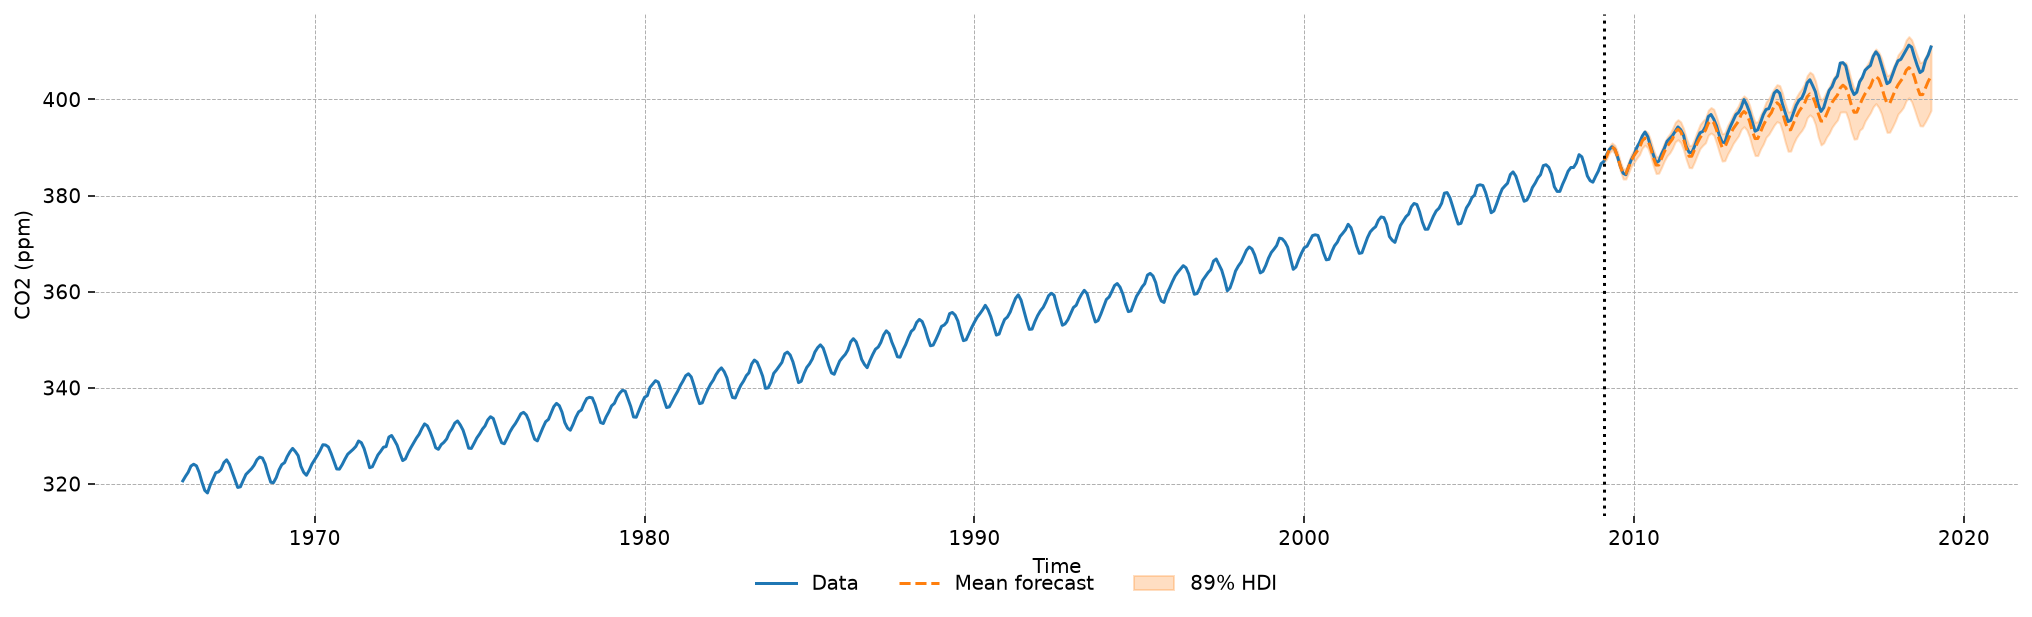

In [9]:
co2_forecast = co2_mod.forecast(
    co2_idata, start=co2_train.index[-1], periods=co2_n_forecast, random_seed=rng
)
co2_forecast_obs = co2_forecast.forecast_observed.isel(observed_state=0)

plot_forecast(co2.co2, co2_forecast_obs, co2_n_forecast, ylabel="CO2 (ppm)");

In [10]:
mae, coverage = forecast_scores(co2.co2.values[-co2_n_forecast:], co2_forecast_obs)
print(f"MAE: {mae:.2f} ppm, held-out months inside the 89% HDI: {coverage:.0%}")

MAE: 2.32 ppm, held-out months inside the 89% HDI: 98%


To see what each part of the model contributes, we draw the smoothed hidden states over the
training period and join them to the forecast of the same states.

Sampling: [filtered_posterior, filtered_posterior_observed, predicted_posterior, predicted_posterior_observed, smoothed_posterior, smoothed_posterior_observed]


Output()

Variables filtered_posterior_observed, predicted_posterior_observed, smoothed_posterior_observed do not contain all hidden states (their last dimension is not 13). They will not be present in the modified idata.


Variables forecast_observed do not contain all hidden states (their last dimension is not 13). They will not be present in the modified idata.


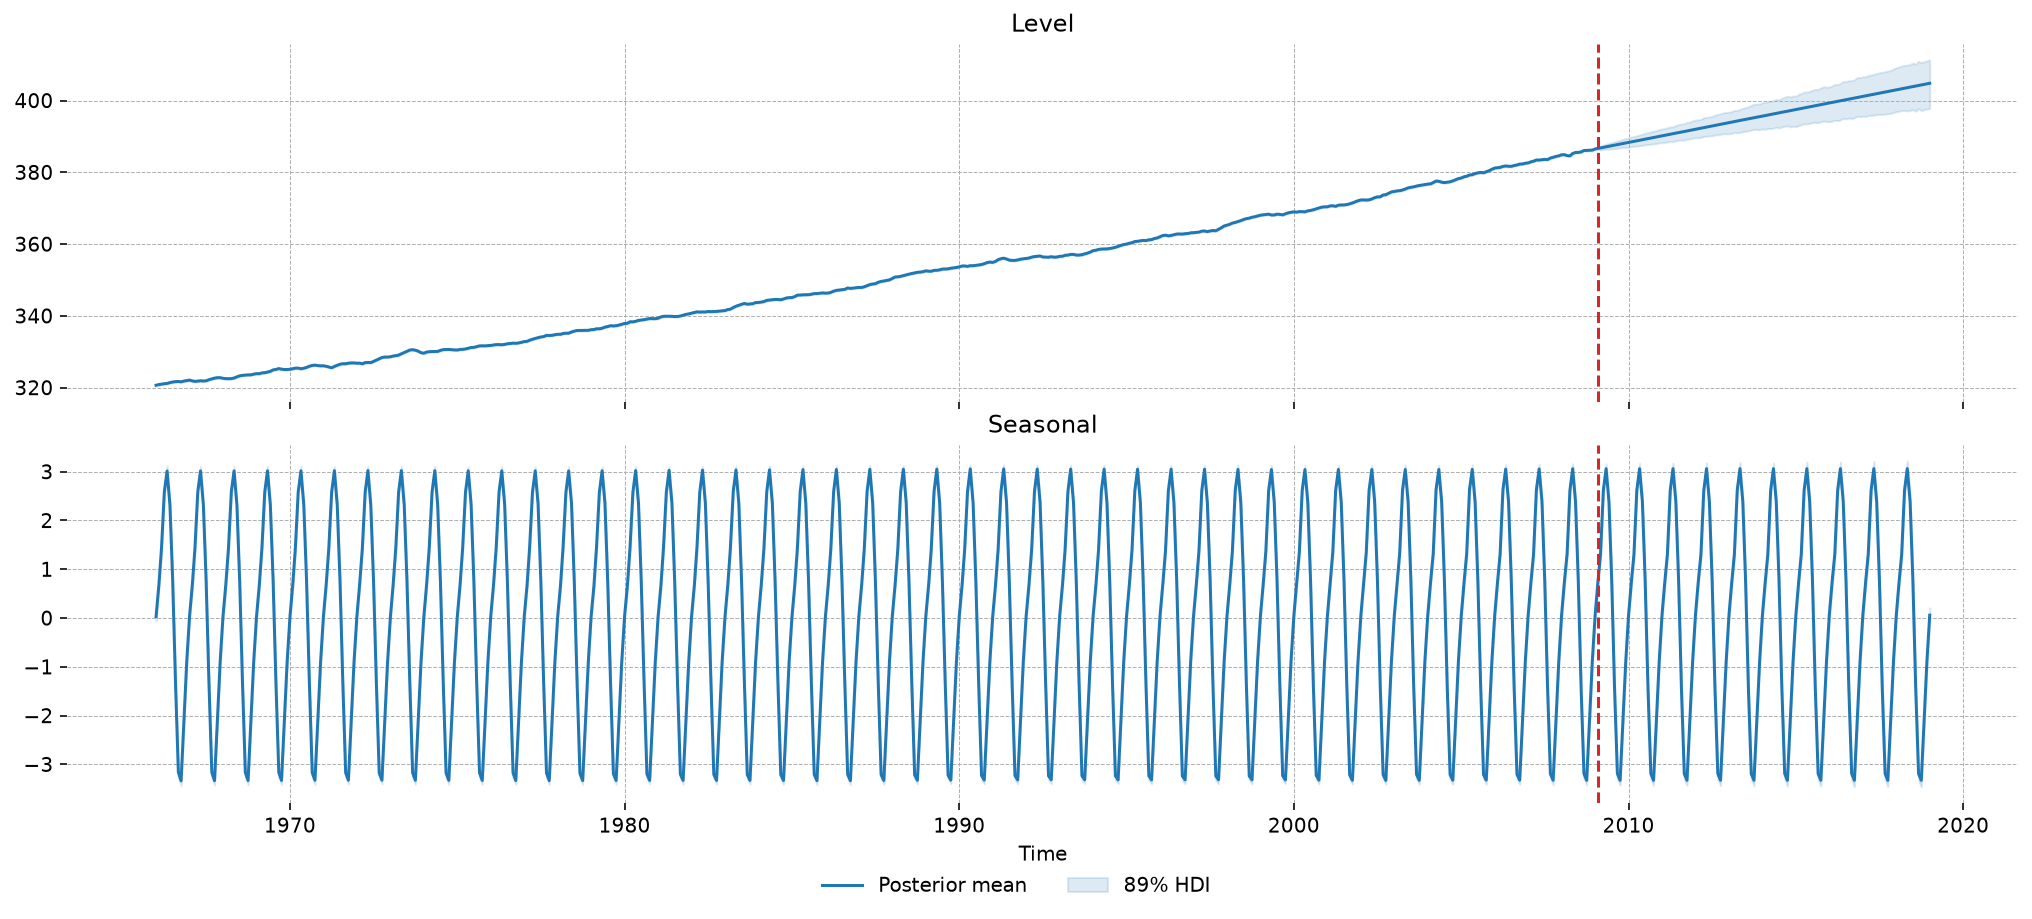

In [11]:
co2_post = co2_mod.sample_conditional_posterior(co2_idata, mvn_method="cholesky", random_seed=rng)
co2_components = co2_mod.extract_components_from_idata(co2_post).smoothed_posterior
co2_forecast_components = co2_mod.extract_components_from_idata(co2_forecast).forecast_latent

co2_decomposition = {
    title: xr.concat(
        [co2_components.sel(state=state), co2_forecast_components.sel(state=state)], dim="time"
    )
    for title, state in [("Level", "trend[level]"), ("Seasonal", "seasonal")]
}
plot_component_decomposition(co2_decomposition, co2.index[-co2_n_forecast], figsize=(14, 6));

## Electricity demand

### Data

Hourly electricity demand in Victoria, Australia, together with the temperature in Melbourne, for
the first eight weeks of 2014. The original series is half-hourly
([fpp2](https://github.com/robjhyndman/fpp2-package)); like the TFP notebook we keep every other
step. The last two weeks are held out.

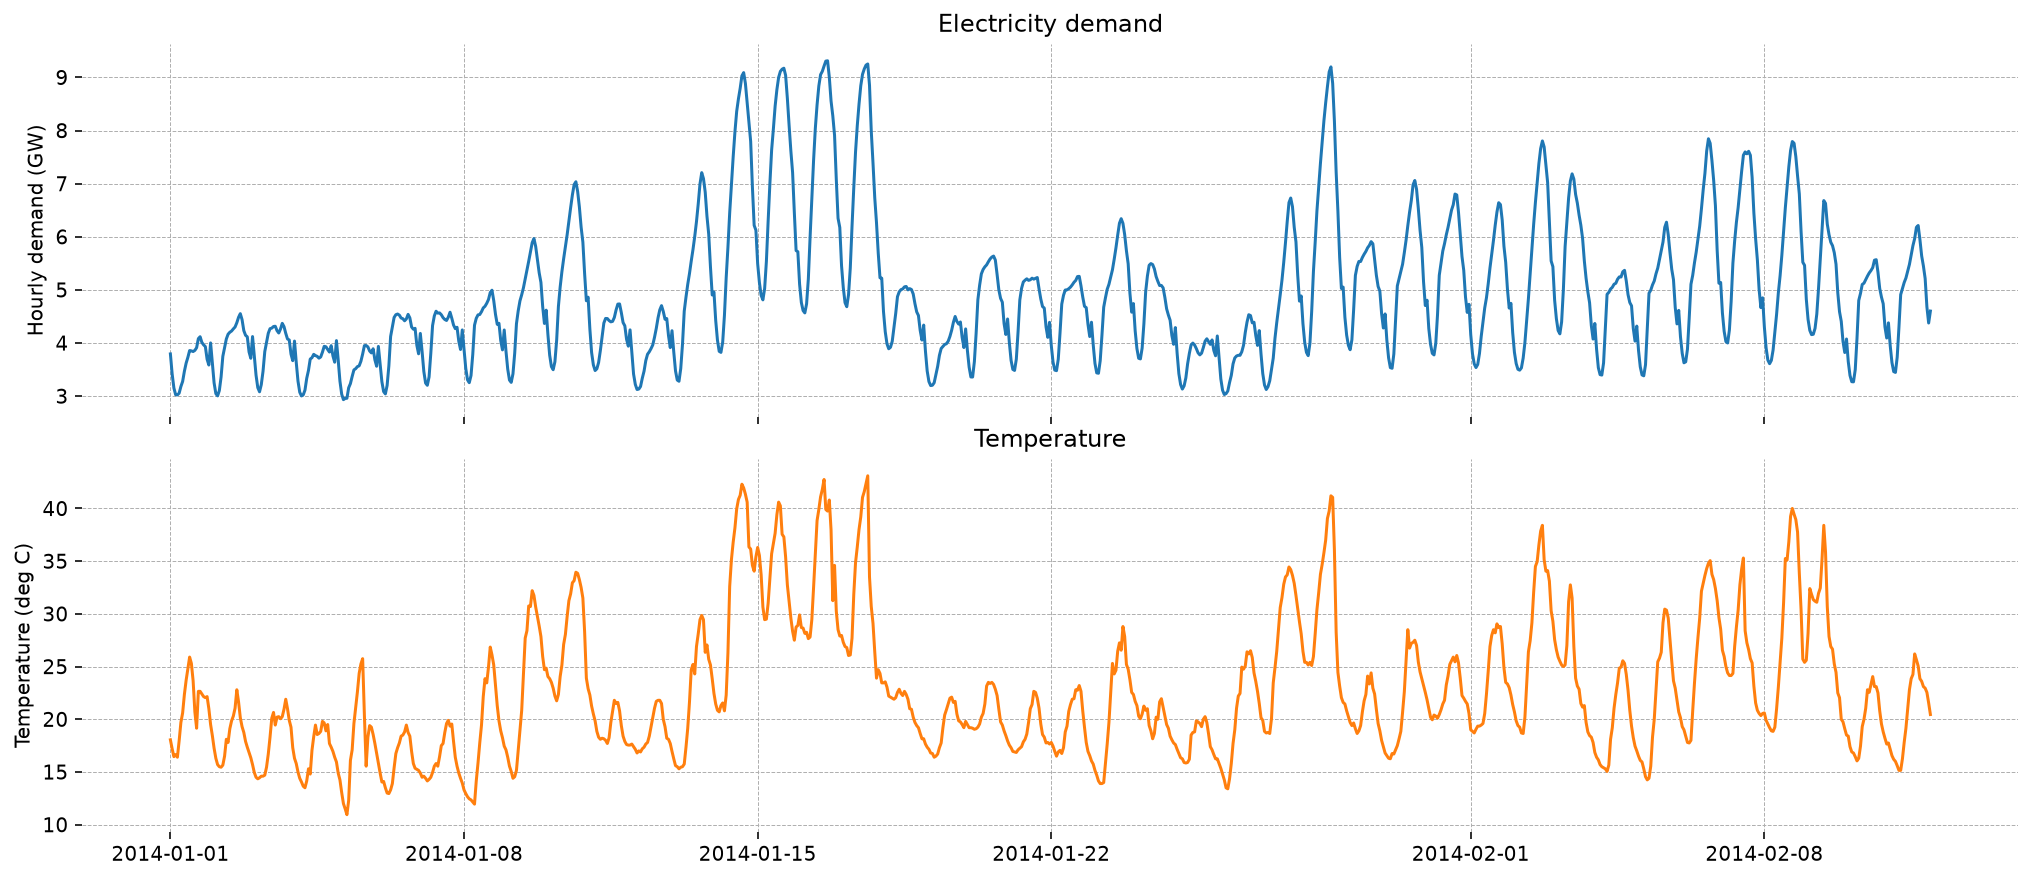

In [12]:
elec = pd.read_csv(
    "../tests/statespace/_data/victoria_electricity.csv", index_col="date", parse_dates=True
)
elec.index.freq = "h"

elec_n_forecast = 24 * 7 * 2
elec_train = elec.iloc[:-elec_n_forecast]

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax[0].plot(elec_train.index, elec_train.demand)
ax[0].set(title="Electricity demand", ylabel="Hourly demand (GW)")
ax[1].plot(elec_train.index, elec_train.temperature, color="tab:orange")
ax[1].set(title="Temperature", ylabel="Temperature (deg C)");

### Model

The TFP model combines an hour-of-day and a day-of-week effect, a linear regression on temperature,
and an AR(1) process for the remaining autocorrelated residuals. The day-of-week effect changes
once every 24 observations, which is `duration=24` in `TimeSeasonality`. Since 1 January 2014 was a
Wednesday, we name the days and set `start_state` so the fitted effects line up with the right
days. As in the original, the temperature is centred before it enters the regression.

In [13]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

elec_mod = (
    st.TimeSeasonality(season_length=24, innovations=True, name="hour")
    + st.TimeSeasonality(
        season_length=7,
        duration=24,
        innovations=True,
        name="day",
        state_names=days,
        start_state="Wed",
    )
    + st.Regression(name="temp", state_names=["temperature"])
    + st.Autoregressive(order=1, name="ar")
    + st.MeasurementError(name="obs")
).build(name="demand")

temperature = (elec.temperature - elec.temperature.mean()).to_frame()

                             Model Requirements                              
                                                                             
  Variable      Shape       Constraints                          Dimensions  
 ─────────────────────────────────────────────────────────────────────────── 
  params_hour   (23,)                                       ('state_hour',)  
  sigma_hour    ()          Positive                                   None  
  params_day    (6,)                                         ('state_day',)  
  sigma_day     ()          Positive                                   None  
  beta_temp     (1,)                                        ('state_temp',)  
  params_ar     (1,)                                            ('lag_ar',)  
  sigma_ar      ()          Positive                                   None  
  sigma_obs     ()          Positive                                   None  
  P0            (31, 31)    Positive semi-definite   ('state', 'state_aux')  
                                                                             
  data_temp     (None, 1)   pm.Data                  ('time', 'state_temp')  
                                                                             
 These parameters should be assigned priors inside a PyMC model block before 
                 calling the build_statespace_graph method.                  

The regression data is passed to the model as `data_temp`. The AR coefficient gets a uniform prior
on $(-1, 1)$, which keeps the process stationary.

Two choices about the initial state covariance `P0` need a word:

- In `Regression`, the coefficient is a hidden state: `beta_temp` is its initial value and `P0`
  says how far the Kalman filter may move it. TFP's `LinearRegression` weight is a plain parameter.
  To match it we pin the coefficient's initial variance to (almost) zero, so `beta_temp` is the
  temperature weight itself.
- Like the TFP model, this one has no intercept: the seasonal effects sum to zero and the
  temperature is centred, so the AR state has to carry the average demand of about 4.5 GW from
  the first hour. The initial variances therefore get a wide prior.

In [14]:
states = list(elec_mod.coords["state"])
pinned = states.index("temperature")
free = [i for i in range(len(states)) if i != pinned]


def elec_priors():
    """Priors for the electricity demand model. Call inside a model context."""
    P0_free = pm.Gamma("P0_diag", alpha=2, beta=0.2, dims=["state_free"])
    P0_diag = pt.set_subtensor(pt.full(len(states), 1e-6)[free], P0_free)
    pm.Deterministic("P0", pt.diag(P0_diag), dims=["state", "state_aux"])

    pm.ZeroSumNormal("params_hour", sigma=2, dims=["state_hour"])
    pm.ZeroSumNormal("params_day", sigma=2, dims=["state_day"])
    pm.Normal("beta_temp", mu=0, sigma=0.5, dims=["state_temp"])
    pm.Uniform("params_ar", lower=-1, upper=1, dims=["lag_ar"])

    pm.HalfNormal("sigma_hour", sigma=0.05)
    pm.HalfNormal("sigma_day", sigma=0.05)
    pm.HalfNormal("sigma_ar", sigma=0.5)
    pm.HalfNormal("sigma_obs", sigma=0.1)


with pm.Model(coords=elec_mod.coords | {"state_free": [states[i] for i in free]}) as elec_model:
    pm.Data("data_temp", temperature.iloc[:-elec_n_forecast].values, dims=["time", "state_temp"])
    elec_priors()

    elec_mod.build_statespace_graph(elec_train[["demand"]])
    # The Kalman filter over 1,008 hours with 31 states is slow, so we draw fewer samples than usual
    elec_idata = pm.sample(tune=500, draws=500, target_accept=0.9, random_seed=rng)

Initializing NUTS using jitter+adapt_diag...


/Users/sakshamarora/Desktop/gsoc/pymc-extras/.venv/lib/python3.12/site-packages/pytensor/link/numba/dispatch/basic.py:234: UserWarning: Numba will use object mode to run Blockwise{ARange{dtype='int64'}, (),(),()->(o00)}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [P0_diag, params_hour, params_day, beta_temp, params_ar, sigma_hour, sigma_day, sigma_ar, sigma_obs]


Output()

In [15]:
az.summary(
    elec_idata,
    var_names=["sigma_hour", "sigma_day", "beta_temp", "params_ar", "sigma_ar", "sigma_obs"],
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
sigma_hour,0.00071,0.00056,5.7e-05,0.0017,2367,1038,1.00,8.9e-06,1.4e-05
sigma_day,0.00202,0.00165,0.00018,0.005,2069,1138,1.00,3e-05,4.7e-05
beta_temp[temperature],0.0564,0.0045,0.049,0.064,3378,1227,1.00,7.8e-05,0.00012
params_ar[1],0.99908,0.00064,1,1,2296,1179,1.00,1.2e-05,1.4e-05
sigma_ar,0.1475,0.0033,0.14,0.15,4476,1376,1.01,4.9e-05,8.4e-05
sigma_obs,0.00315,0.0023,0.00026,0.0073,1982,985,1.00,4.1e-05,5.2e-05


The TFP notebook reports:

| parameter | TFP |
|---|---|
| observation noise | 0.010 |
| hour-of-day drift scale | 0.0020 |
| day-of-week drift scale | 0.013 |
| temperature weight | 0.066 |
| AR coefficient | 0.987 |
| AR innovation scale | 0.142 |

The temperature weight and the AR innovation scale agree closely. As with the CO2 model, the
seasonal drift scales are defined differently in the two libraries and are not directly
comparable. The AR coefficient sits even closer to one here than in the TFP fit: with no intercept
in the model, the AR process is what carries the level of demand, and NUTS finds it behaving
almost like a random walk.

### Forecasting and criticism

The forecast needs the temperature over the forecast window, which we pass as a scenario.

Sampling: [forecast_combined]


Output()

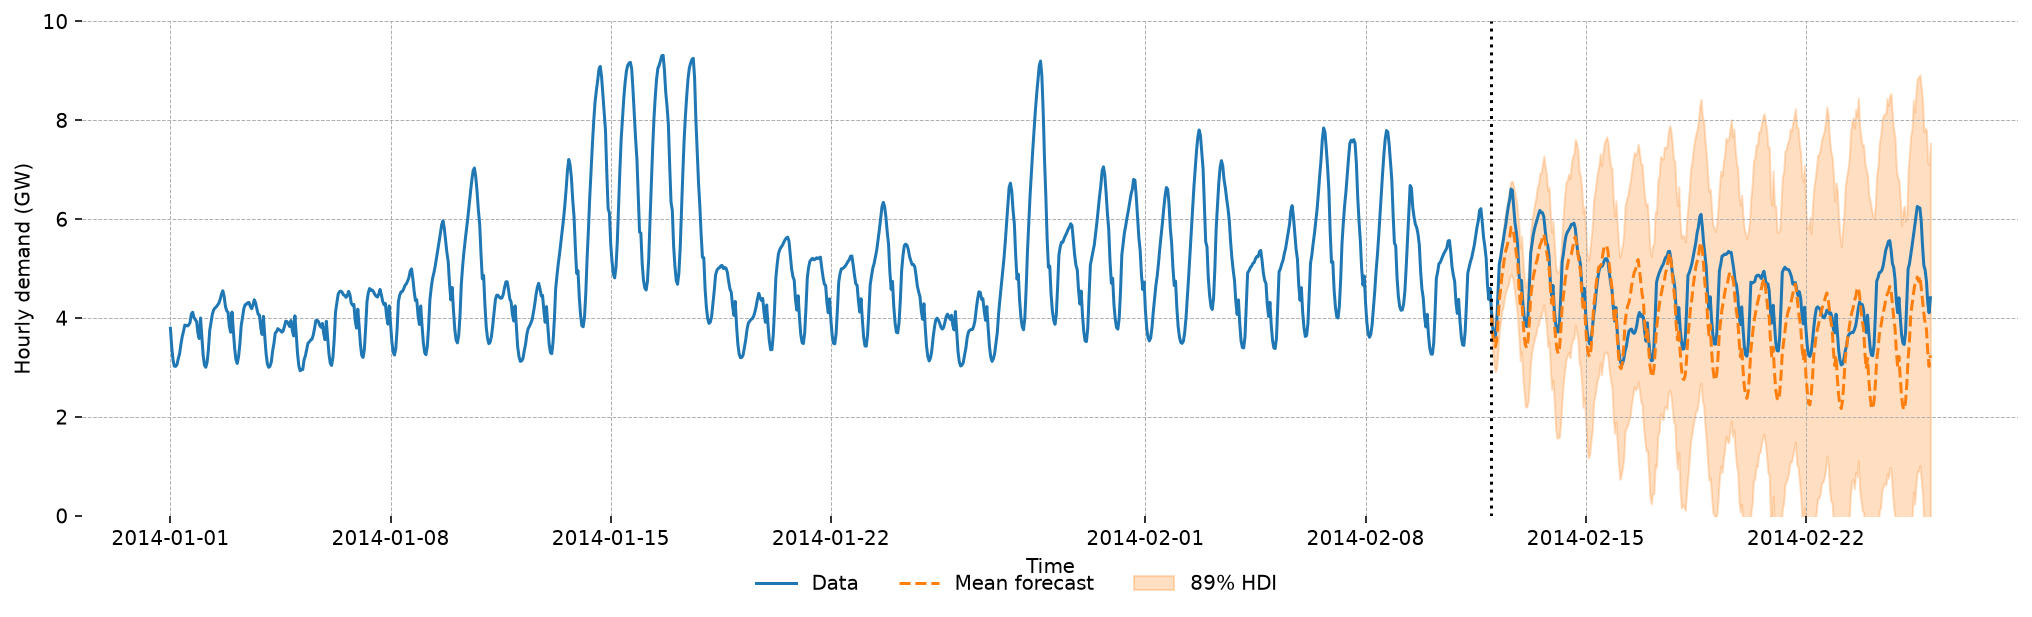

In [16]:
elec_forecast = elec_mod.forecast(
    elec_idata,
    start=elec_train.index[-1],
    periods=elec_n_forecast,
    scenario={"data_temp": temperature.iloc[-elec_n_forecast:]},
    random_seed=rng,
)
elec_forecast_obs = elec_forecast.forecast_observed.isel(observed_state=0)

fig = plot_forecast(elec.demand, elec_forecast_obs, elec_n_forecast, ylabel="Hourly demand (GW)")
fig.axes[0].set_ylim(0, 10);

In [17]:
mae, coverage = forecast_scores(elec.demand.values[-elec_n_forecast:], elec_forecast_obs)
print(f"MAE: {mae:.3f} GW, held-out hours inside the 89% HDI: {coverage:.0%}")

MAE: 0.612 GW, held-out hours inside the 89% HDI: 99%


The regression state holds the temperature coefficient, so its contribution to demand is that
state times the temperature.

Sampling: [filtered_posterior, filtered_posterior_observed, predicted_posterior, predicted_posterior_observed, smoothed_posterior, smoothed_posterior_observed]


Output()

Variables filtered_posterior_observed, predicted_posterior_observed, smoothed_posterior_observed do not contain all hidden states (their last dimension is not 31). They will not be present in the modified idata.


Variables forecast_observed do not contain all hidden states (their last dimension is not 31). They will not be present in the modified idata.


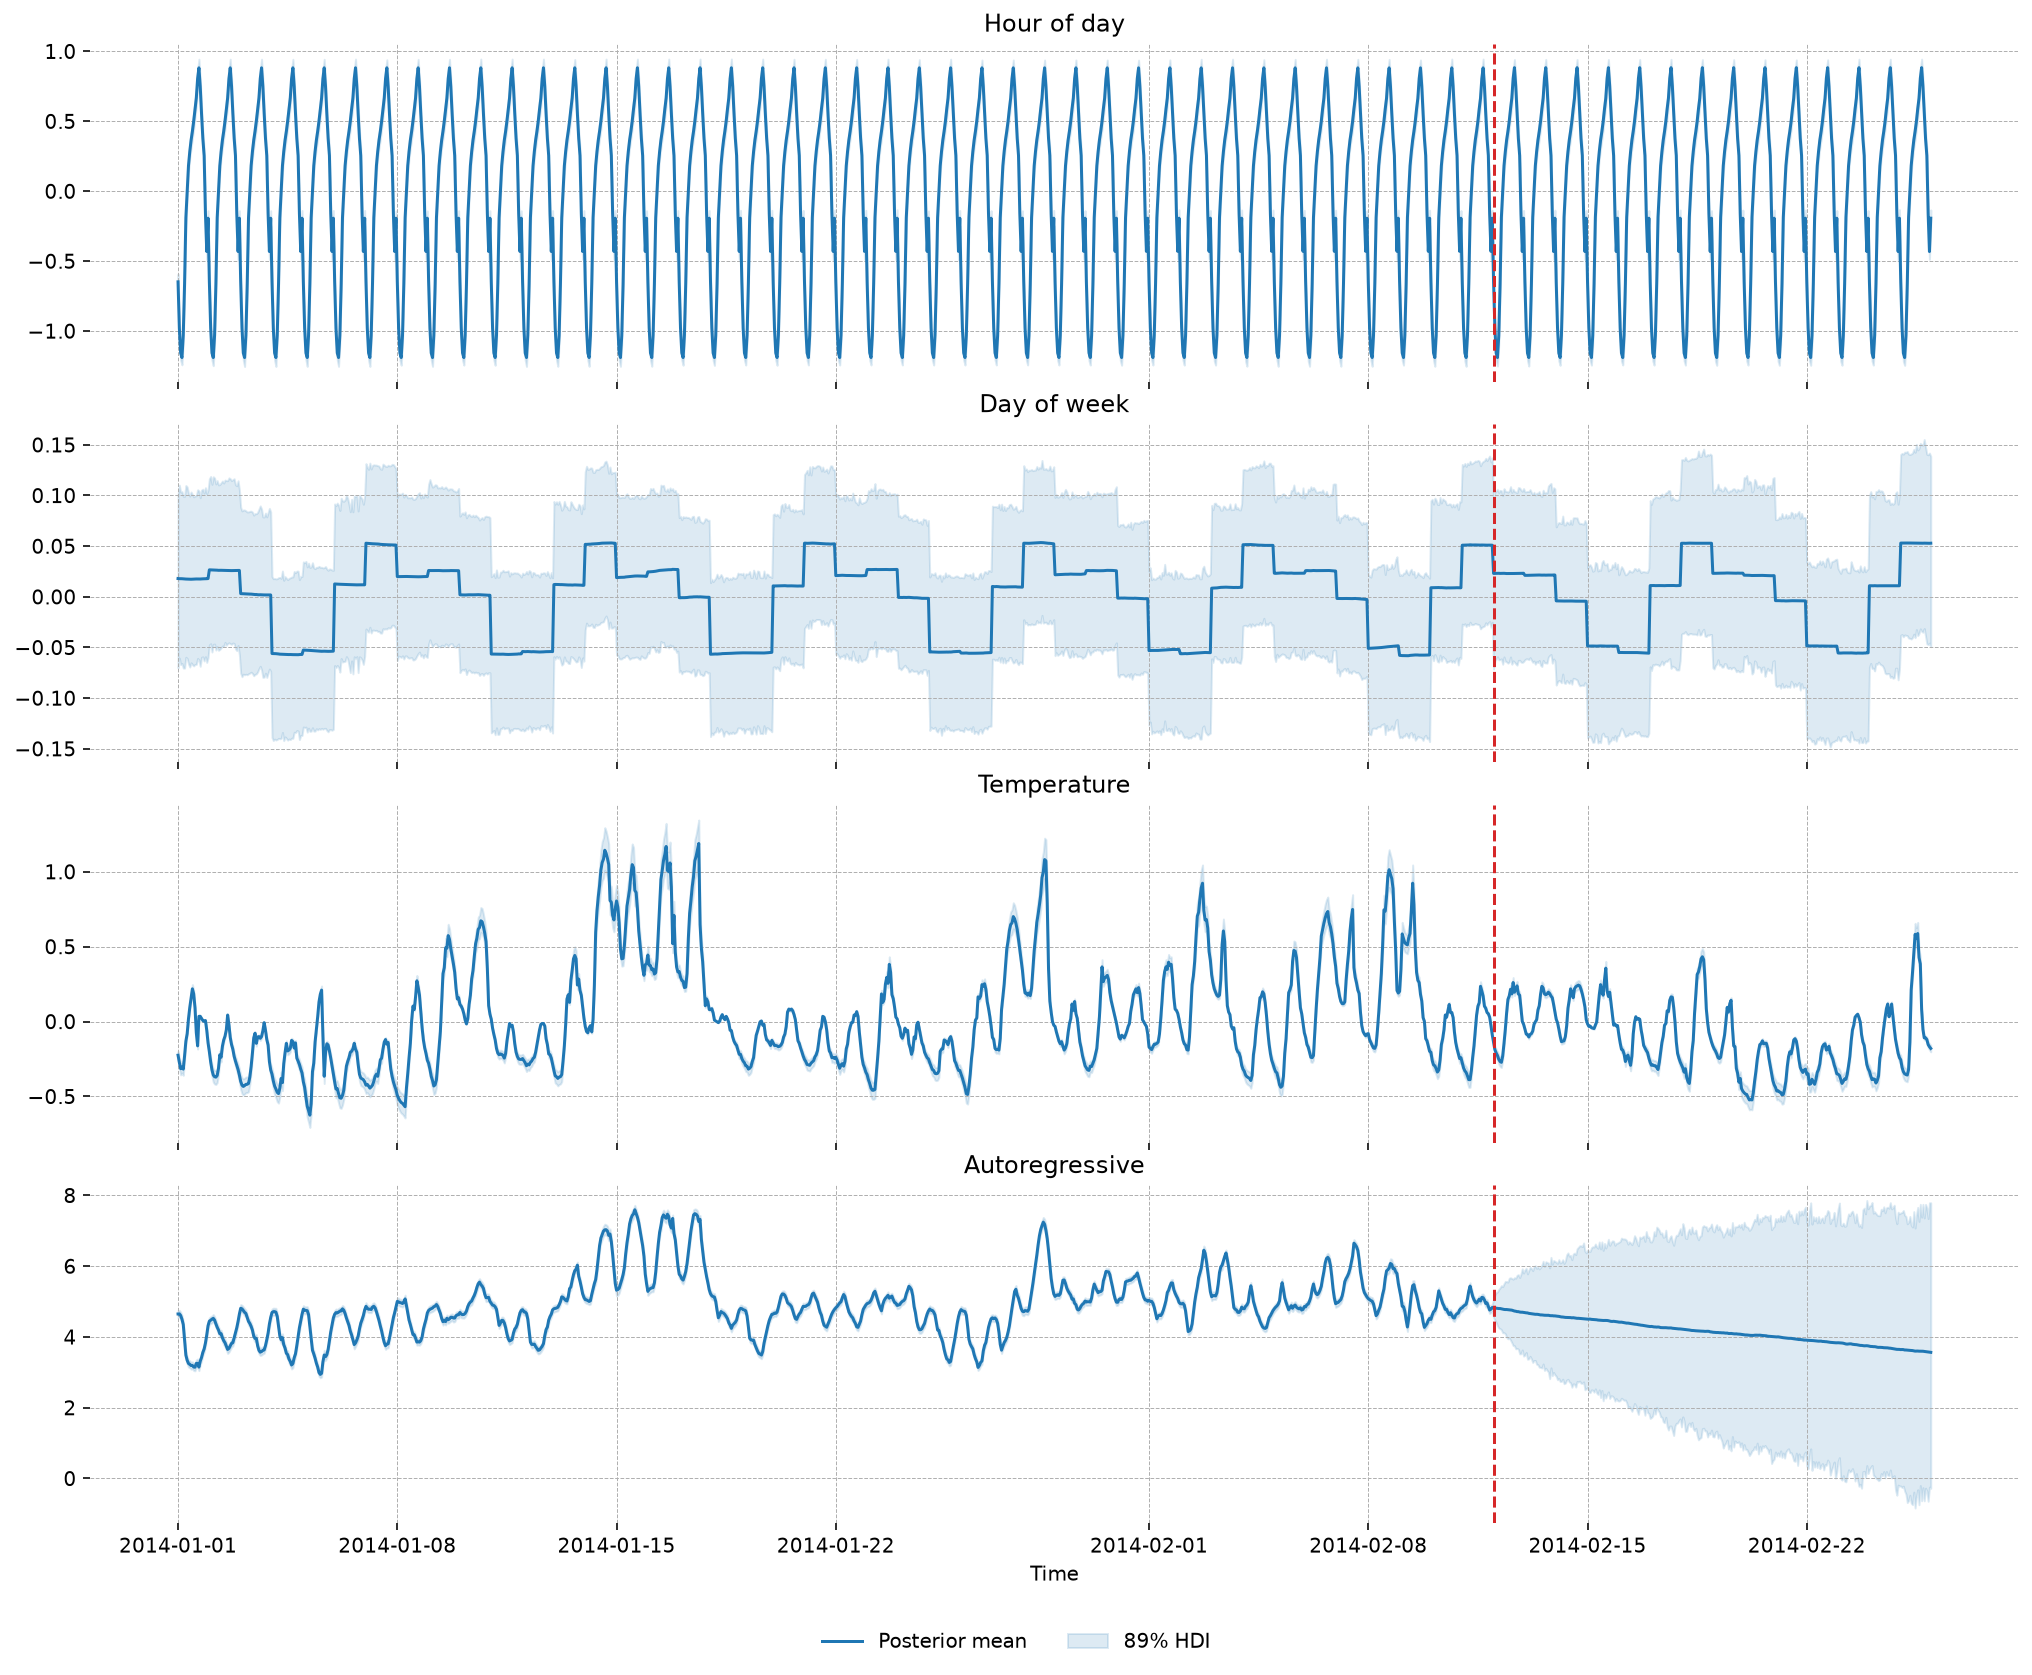

In [18]:
# The pinned regression state makes the smoothed covariances nearly singular, which a Cholesky
# factorisation cannot handle, so we keep the default SVD here.
elec_post = elec_mod.sample_conditional_posterior(elec_idata, random_seed=rng)
elec_components = elec_mod.extract_components_from_idata(elec_post).smoothed_posterior
elec_forecast_components = elec_mod.extract_components_from_idata(elec_forecast).forecast_latent

elec_decomposition = {
    title: xr.concat(
        [elec_components.sel(state=state), elec_forecast_components.sel(state=state)], dim="time"
    )
    for title, state in [
        ("Hour of day", "hour"),
        ("Day of week", "day"),
        ("Temperature", "temp[temperature]"),
        ("Autoregressive", "ar"),
    ]
}
temp_values = xr.DataArray(
    temperature.temperature.values, dims=["time"], coords={"time": elec.index.values}
)
elec_decomposition["Temperature"] = elec_decomposition["Temperature"] * temp_values

fig = plot_component_decomposition(
    elec_decomposition, elec.index[-elec_n_forecast], figsize=(14, 11)
)

### Anomaly detection

The one-step-ahead predictions of the Kalman filter give, for every hour, a forecast using only
the hours before it. Hours far from their prediction are the ones the model finds most surprising.
Following the TFP notebook we run the filter over the whole series, held-out weeks included, using
the posterior draws from the fit above. `make_filter_outputs` builds the filter on the full data
inside a new model with the same priors, and `sample_posterior_predictive` evaluates it on each
posterior draw.

In [19]:
with pm.Model(
    coords=elec_mod.coords | {"state_free": [states[i] for i in free]}
) as elec_full_model:
    pm.Data("data_temp", temperature.values, dims=["time", "state_temp"])
    elec_priors()
    elec_mod.build_statespace_graph(elec[["demand"]])

    outputs = elec_mod.make_filter_outputs(
        ["predicted_observed_states", "predicted_observed_covariances"]
    )
    pm.Deterministic("one_step_mean", outputs["predicted_observed_states"][:, 0], dims=["time"])
    pm.Deterministic(
        "one_step_var", outputs["predicted_observed_covariances"][:, 0, 0], dims=["time"]
    )

    one_step = pm.sample_posterior_predictive(
        elec_idata, var_names=["one_step_mean", "one_step_var"], random_seed=rng
    ).posterior_predictive

Sampling: []


Output()

Averaging over the posterior draws, the predictive variance is the mean of the per-draw variances
plus the variance of the per-draw means.

7 anomalous hours


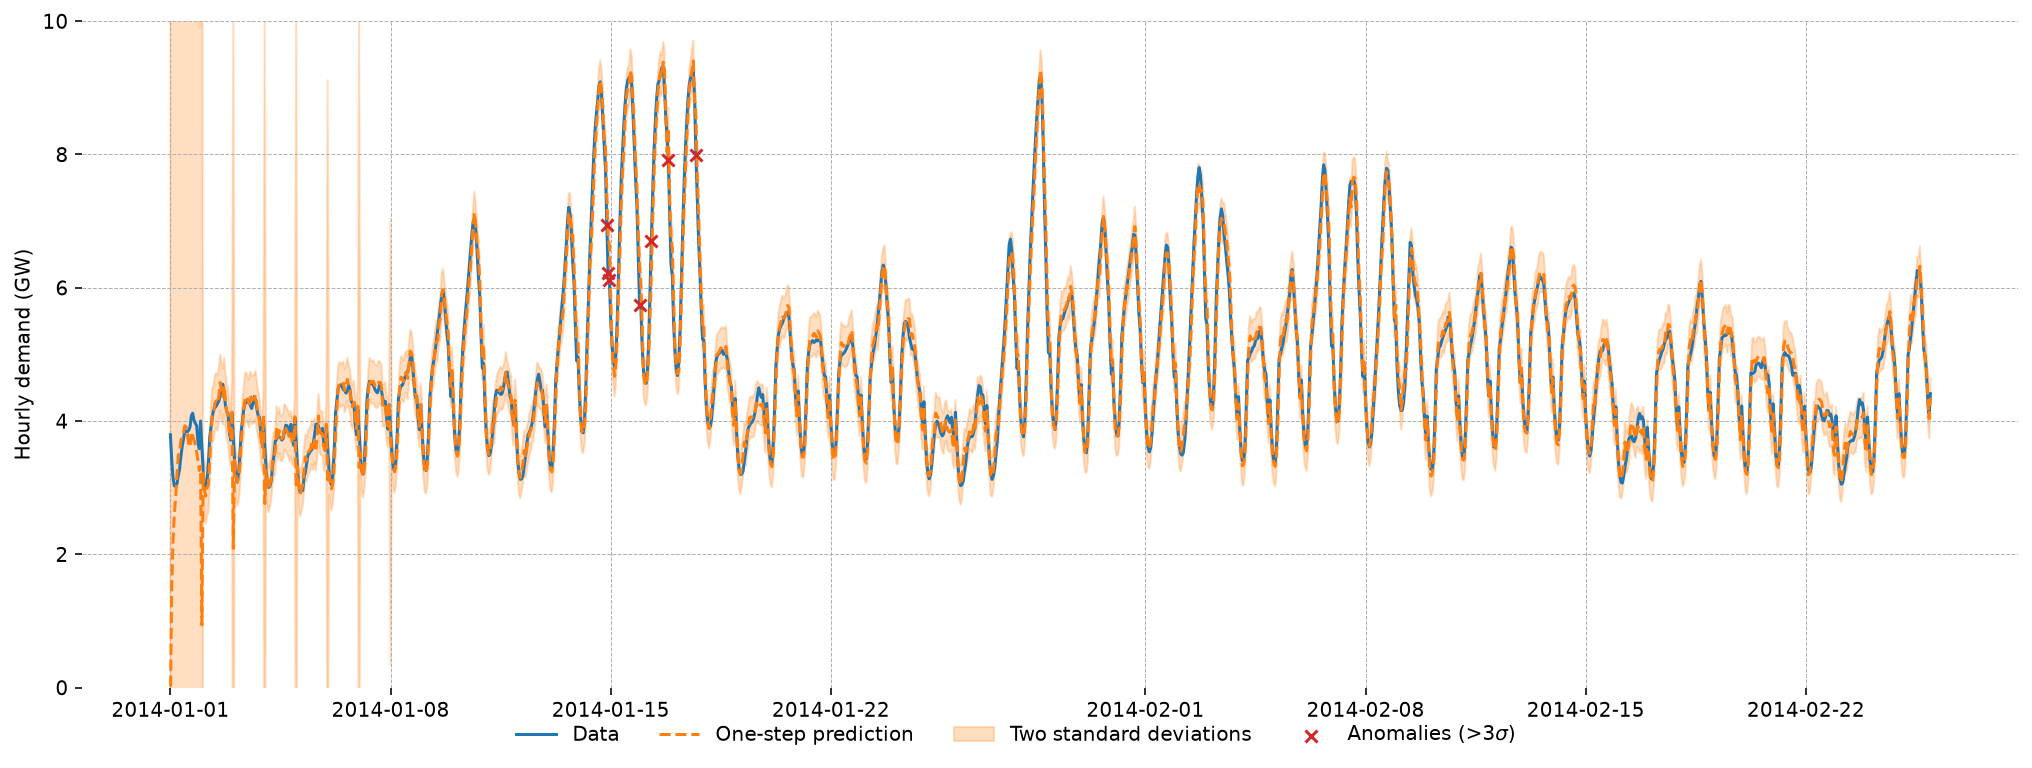

In [20]:
one_step_mean = one_step.one_step_mean.mean(dim=["chain", "draw"])
one_step_sd = np.sqrt(
    one_step.one_step_var.mean(dim=["chain", "draw"])
    + one_step.one_step_mean.var(dim=["chain", "draw"])
)

zscores = np.abs((elec.demand.values - one_step_mean.values) / one_step_sd.values)
anomalies = zscores > 3.0

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(elec.index, elec.demand, label="Data")
ax.plot(elec.index, one_step_mean, color="tab:orange", ls="--", label="One-step prediction")
ax.fill_between(
    elec.index,
    one_step_mean - 2 * one_step_sd,
    one_step_mean + 2 * one_step_sd,
    color="tab:orange",
    alpha=0.25,
    label="Two standard deviations",
)
ax.scatter(
    elec.index[anomalies],
    elec.demand[anomalies],
    color="tab:red",
    marker="x",
    zorder=3,
    label=r"Anomalies (>3$\sigma$)",
)
ax.set(ylabel="Hourly demand (GW)", ylim=(0, 10))
add_figure_legend(fig, ax)
print(f"{anomalies.sum()} anomalous hours")

The flagged hours fall in the heatwave of 14 to 17 January, as in the TFP notebook. The wide
bands during the first week are the filter starting up: each day-of-week effect is uncertain until
that day has been seen once.

## Authors
- Ported from the TensorFlow Probability case study by Saksham Arora, November 2026